# Phase 3: Weather and Hat Sales â€” Regression Analysis

**Course:** INFO 2950 | **Business:** angelawilliam.com | **Period:** 2014-2026


## 1. Introduction

This analysis examines whether U.S. monthly temperature and precipitation predict
monthly hat sales at angelawilliam.com, a family-owned hat business based in
Farmingdale, NY that ships nationwide. Because the customer base is geographically
distributed, national weather averages (rather than local Farmingdale weather)
are an appropriate predictor.

The business operates on a B2B model: many customers are retailers or wholesalers
who purchase ahead of expected seasonal weather rather than in response to current
conditions. This forward-buying behavior may attenuate or introduce a lag in the
relationship between current weather and recorded sales. Our models use contemporaneous
weather as a first step; lag analysis is noted as a future direction.

**Research question:** How do U.S. monthly temperature and precipitation relate to
the business's monthly hat sales, and does this relationship vary between cotton
and wool hat materials?

**Summary of findings:** We fit two least squares regression models on January 2014 to
August 2026 data, controlling for seasonality (calendar-month dummies) and a
linear year trend. Model 1 regresses log monthly identified-material hat quantity
on temperature and precipitation. Model 2 regresses the cotton share of
cotton-plus-wool sales on the same predictors. Results and significance evaluations
are in Sections 5 and 6.


## 2. Setup


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 4)


In [4]:
# All analysis data comes from the two CSVs produced by data_cleaning.ipynb.
analysis_data = pd.read_csv('csvs/analysis_data.csv', parse_dates=['month'])
weather_monthly = pd.read_csv('csvs/weather_monthly.csv', parse_dates=['month'])

print('analysis_data shape:', analysis_data.shape)
print('columns:', list(analysis_data.columns))
print('date range:', analysis_data['month'].min().strftime('%Y-%m'),
      'to', analysis_data['month'].max().strftime('%Y-%m'))
print()
print('weather_monthly shape:', weather_monthly.shape)
display(analysis_data.head())


analysis_data shape: (567, 5)
columns: ['month', 'material', 'recorded_quantity', 'temperature_c', 'precipitation_mm']
date range: 2014-01 to 2026-08

weather_monthly shape: (232, 3)


,month,material,recorded_quantity,temperature_c,precipitation_mm
0,2014-01-01,wool,36,-0.800000,34.798
1,2014-03-01,cotton,762,4.727778,60.198
2,2014-03-01,straw,48,4.727778,60.198
3,2014-04-01,cotton,1272,10.938889,72.898
4,2014-04-01,straw,48,10.938889,72.898


## 3. Data Description

### 3.1 About the dataset

**What does our dataset contain?**

`analysis_data.csv` has rows covering months of identified-material sales records from
January 2014 through August 2026. Each row is the total recorded sales quantity for
one hat material in one month. Only rows with an identified material (acrylic, cotton,
felt, leather, polyester, straw, wool) are included; rows with unknown or ambiguous
material are excluded.

| Column | Meaning |
| --- | --- |
| `month` | First day of the month. |
| `material` | Hat material (one of seven identified categories). |
| `recorded_quantity` | Total recorded positive sales quantity for that material that month. |
| `temperature_c` | CONUS average monthly temperature (degrees C). |
| `precipitation_mm` | CONUS area-average monthly precipitation (mm). |

`weather_monthly.csv` covers the full sales period (October 2006 to August 2026).

The cleaning notebook that produced these files:
[data_cleaning.ipynb](https://github.com/bobbybotbop/INFO2950/blob/main/data_cleaning.ipynb)

**Why was this dataset created?**

The sales data were originally collected for accounting purposes by the business.
NOAA maintains the weather data as a public record of historical climate. We combined
them to investigate whether weather conditions relate to hat sales patterns.

**How was the dataset created?**

Raw sales exports were filtered to invoice rows with positive quantities, matched to
a product catalog to identify hats, and classified by material using HTML fields from
the web-store catalog. Sales were aggregated by
month and material. NOAA monthly climate data were reshaped,
converted to metric units, and merged on month. The full pipeline is in
`data_cleaning.ipynb`.

**What factors might affect what was recorded?**

Sales represent purchases actually processed by the business, not total customer
demand. Out-of-stock items would not appear. The accounting exports may be
incomplete (both hit the 32,768-row export limit). Only 11.9% of recorded
quantity has an identified material â€” the remaining 88.1% is classified unknown
or mixed/ambiguous due to a historical documentation gap in the pre-online-store era.

**What preprocessing was done?**

Invoice rows were filtered; dates and quantities were parsed; products were identified
as hats; materials were classified via catalog HTML fields with keyword fallback;
quantities were aggregated by month and material; unknown/ambiguous material rows
were excluded; the data were restricted to 2014 onward.

**Were people aware their data was being collected?**

The sales records are from normal business operations; we received them from the owner
with permission. The data contain no individual customer information. NOAA weather
data are public domain.

**Where can the original data be found?**

NOAA climate division data: https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/
Business data: private; project CSVs are in the GitHub `csvs/` folder.

*Note on unknown materials:* 88.1% of recorded sales quantity has unknown or ambiguous
material, largely because the business did not document product materials before moving
online. This motivates the 2014+ restriction where known-material coverage first exceeds
10% of annual quantity.

### 3.2 Exploratory data analysis

The plots below are generated from `analysis_data.csv` (identified-material sales, 2014+).


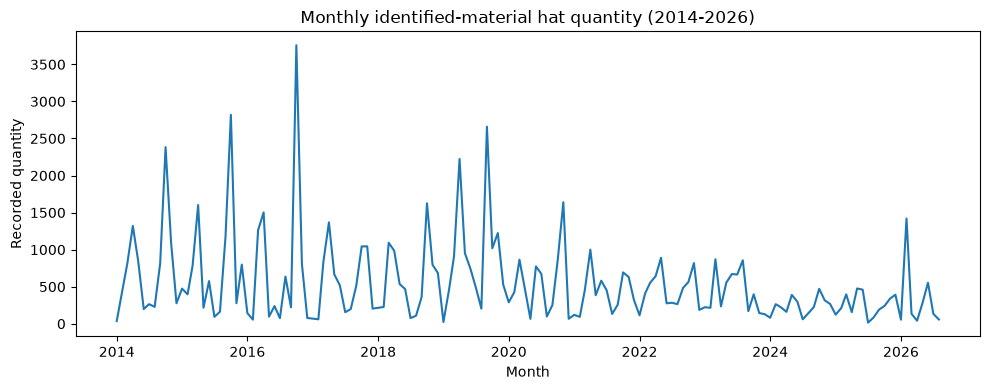

In [5]:
monthly_totals = analysis_data.groupby('month')['recorded_quantity'].sum().reset_index()

plt.figure(figsize=(10, 4))
plt.plot(monthly_totals['month'], monthly_totals['recorded_quantity'])
plt.title('Monthly identified-material hat quantity (2014-2026)')
plt.xlabel('Month')
plt.ylabel('Recorded quantity')
plt.tight_layout()
plt.show()


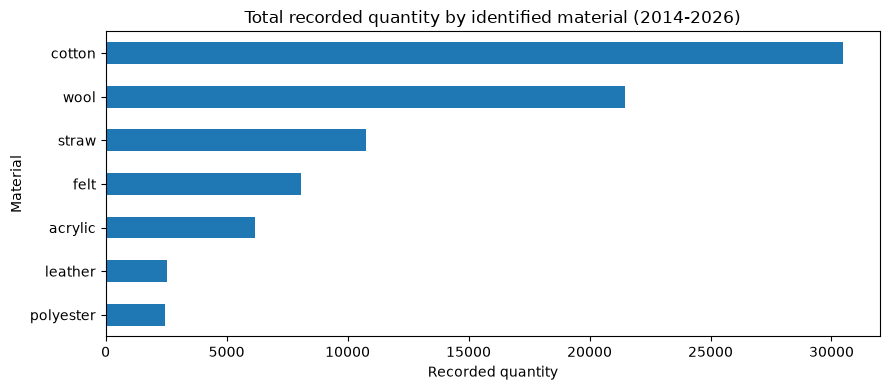

In [6]:
material_totals = (analysis_data.groupby('material')['recorded_quantity']
                   .sum().sort_values())

material_totals.plot(kind='barh', figsize=(9, 4))
plt.title('Total recorded quantity by identified material (2014-2026)')
plt.xlabel('Recorded quantity')
plt.ylabel('Material')
plt.tight_layout()
plt.show()


Cotton and wool are the two largest identified-material categories, which motivates
their use in Model 2. Sales show year-over-year variability; the 2014-2026 trend reflects
the period where identified-material coverage is most reliable.


## 4. Preregistration Statements

The following hypotheses and analyses were registered before examining the
weather-sales relationship.

---

**Preregistration Statement 1: Weather and total monthly sales**

*Hypothesis:* We expect lower temperatures to be associated with higher monthly hat
sales, even after accounting for seasonality and changes over time. We also expect
precipitation to have a relationship with sales, although we do not have a strong
prediction about its direction.

*Proposed analysis:* We will calculate total recorded hat quantity per month and use
multiple linear regression to examine its relationship with temperature and precipitation.
The dependent variable will be the log of monthly sales quantity; the independent variables
will be temperature, precipitation, calendar month (as dummies), and year. We predict
a negative temperature coefficient (beta_temperature < 0) and a nonzero precipitation
coefficient (beta_precipitation != 0).

---

**Preregistration Statement 2: Weather and cotton-wool sales mix**

*Hypothesis:* Cotton hats make up a larger share of sales relative to wool hats during
warmer months, even after accounting for precipitation, seasonal patterns, and year.

*Proposed analysis:* For each month, we calculate the proportion of cotton quantity out of
combined cotton and wool quantity. Months where neither material has recorded sales are
excluded (the proportion would be undefined). We then regress this proportion on temperature,
precipitation, calendar month (as dummies), and year. We predict a positive temperature
coefficient (beta_temperature > 0).


## 5. Data Analysis

Both models use data from `analysis_data.csv` (January 2014 - August 2026). This period
is the most defensible for regression: 2014 is the first year where identified-material
quantity exceeds 10% of annual recorded quantity (documented in `data_cleaning.ipynb`).

We use `statsmodels.formula.api.ols` with calendar-month dummies (`C(month_num)`, with
January as the omitted reference category) and `year_num` as a linear trend control.
We interpret results using the summarizing, predicting, and outlier-assessment framework.


### 5.1 Model 1: Log monthly hat quantity vs. weather

**Dependent variable:** log(total monthly identified-material hat quantity)
**Predictors:** temperature (C), precipitation (mm), calendar-month dummies, year

We log-transform quantity to handle the right-skewed distribution of monthly sales totals,
as preregistered. The unit of observation is one row per month (quantity summed across
all identified materials).


In [7]:
# Aggregate to one row per month (sum across all identified materials).
monthly_totals = analysis_data.groupby('month')['recorded_quantity'].sum().reset_index()
weather_by_month = (analysis_data[['month', 'temperature_c', 'precipitation_mm']]
                    .drop_duplicates('month'))
model1_data = monthly_totals.merge(weather_by_month, on='month', validate='one_to_one')
model1_data['log_quantity'] = np.log(model1_data['recorded_quantity'])
model1_data['month_num'] = model1_data['month'].dt.month
model1_data['year_num'] = model1_data['month'].dt.year

print('Model 1 observations:', len(model1_data))
print('Date range:', model1_data['month'].min().strftime('%Y-%m'),
      'to', model1_data['month'].max().strftime('%Y-%m'))
display(model1_data[['log_quantity', 'temperature_c', 'precipitation_mm']].describe().round(3))


Model 1 observations: 148
Date range: 2014-01 to 2026-08


,log_quantity,temperature_c,precipitation_mm
count,148.000,148.000,148.000
mean,5.852,12.649,66.411
std,1.028,8.318,15.571
min,2.708,-1.578,24.384
25%,5.251,4.736,56.515
50%,5.976,12.514,66.040
75%,6.666,20.631,76.264
max,8.232,24.950,113.538


In [8]:
model1 = smf.ols(
    'log_quantity ~ temperature_c + precipitation_mm + C(month_num) + year_num',
    data=model1_data
).fit()

print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.420
Model:                            OLS   Adj. R-squared:                  0.359
Method:                 Least Squares   F-statistic:                     6.874
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           1.92e-10
Time:                        21:59:40   Log-Likelihood:                -173.24
No. Observations:                 148   AIC:                             376.5
Df Residuals:                     133   BIC:                             421.4
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            132.3648     39

#### Interpretation of Model 1

The regression summary above reports the regression of log monthly identified-material hat
quantity on temperature, precipitation, calendar-month dummies, and year (January 2014
to August 2026, N shown above).

**Summarizing:** The R-squared value (shown in the summary header) indicates how much
variation in log monthly sales is explained by the full model. The month dummies likely
capture the dominant seasonal patterns; temperature and precipitation describe the
additional weather component after controlling for season and year.

**Temperature coefficient:** The temperature coefficient (`temperature_c`) shows the
estimated change in log monthly quantity per 1-degree-C increase in average national
temperature, holding precipitation, month, and year fixed. A negative coefficient would
support the preregistered prediction (beta_temperature < 0), meaning cooler months are
associated with higher hat sales. The p-value in the summary indicates whether this
coefficient is statistically significant at alpha = 0.05.

**Precipitation coefficient:** The precipitation coefficient (`precipitation_mm`) shows
the estimated change in log monthly quantity per 1 mm increase in average monthly
precipitation, holding the other predictors fixed. A p-value below 0.05 would support
the preregistered prediction of a nonzero effect.

**Predicting:** The model can be used to predict log monthly sales for any combination
of weather conditions, season, and year. Predictions outside the 2014-2026 range should
be treated with caution.

**Outliers:** The residuals-vs-fitted plot below highlights any months with unusually large residuals.


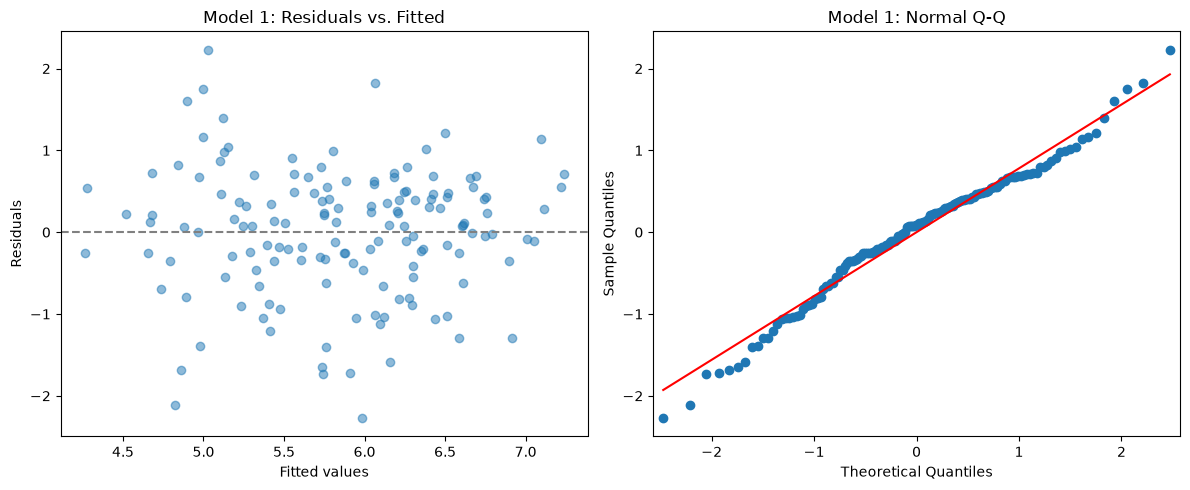

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))

fitted1 = model1.fittedvalues
resid1 = model1.resid

ax.scatter(fitted1, resid1, alpha=0.5)
ax.axhline(0, linestyle='--', color='gray')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Model 1: Residuals vs. Fitted')


plt.tight_layout()
plt.show()


### 5.2 Model 2: Cotton proportion of cotton+wool sales vs. weather

**Dependent variable:** cotton quantity / (cotton + wool quantity) per month
**Predictors:** temperature (C), precipitation (mm), calendar-month dummies, year
**Restriction:** months where neither cotton nor wool has recorded sales are excluded,
since the proportion is undefined in those months (no information about the cotton-wool mix).


In [10]:
cotton = (analysis_data[analysis_data['material'] == 'cotton']
          [['month', 'recorded_quantity']]
          .rename(columns={'recorded_quantity': 'cotton_qty'}))
wool = (analysis_data[analysis_data['material'] == 'wool']
        [['month', 'recorded_quantity']]
        .rename(columns={'recorded_quantity': 'wool_qty'}))

model2_data = (cotton.merge(wool, on='month', how='outer')
               .fillna({'cotton_qty': 0, 'wool_qty': 0}))
model2_data = model2_data.merge(weather_by_month, on='month', how='inner')
model2_data['total_cw'] = model2_data['cotton_qty'] + model2_data['wool_qty']

dropped = (model2_data['total_cw'] == 0).sum()
model2_data = model2_data[model2_data['total_cw'] > 0].copy()
print(f'Dropped {dropped} months where neither cotton nor wool had recorded sales.')

model2_data['cotton_proportion'] = model2_data['cotton_qty'] / model2_data['total_cw']
model2_data['month_num'] = model2_data['month'].dt.month
model2_data['year_num'] = model2_data['month'].dt.year

print('Model 2 observations:', len(model2_data))
display(model2_data[['cotton_proportion', 'temperature_c', 'precipitation_mm']].describe().round(3))


Dropped 0 months where neither cotton nor wool had recorded sales.
Model 2 observations: 141


,cotton_proportion,temperature_c,precipitation_mm
count,141.000,141.000,141.000
mean,0.613,12.850,66.242
std,0.404,8.165,15.323
min,0.000,-1.578,24.384
25%,0.208,4.978,56.896
50%,0.807,12.650,66.040
75%,1.000,20.872,76.200
max,1.000,24.950,113.538


In [11]:
model2 = smf.ols(
    'cotton_proportion ~ temperature_c + precipitation_mm + C(month_num) + year_num',
    data=model2_data
).fit()

print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:      cotton_proportion   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.712
Method:                 Least Squares   F-statistic:                     25.75
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.25e-30
Time:                        21:59:40   Log-Likelihood:                 23.323
No. Observations:                 141   AIC:                            -16.65
Df Residuals:                     126   BIC:                             27.59
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             38.7308     10

#### Interpretation of Model 2

The regression summary above reports the regression of monthly cotton proportion
(cotton / (cotton + wool) quantity) on temperature, precipitation, calendar-month dummies,
and year (months with positive cotton-or-wool sales, N shown above).

**Summarizing:** The R-squared indicates how much variation in the cotton-wool mix is
explained by the predictors. Because the dependent variable is a proportion bounded to
[0, 1], the least squares intercept and coefficients should be interpreted as a linear approximation;
predictions below 0 or above 1 are not meaningful.

**Temperature coefficient:** The temperature coefficient shows the estimated change in
cotton proportion per 1-degree-C increase in average national temperature, holding
precipitation, month, and year fixed. A positive coefficient would support the
preregistered prediction (beta_temperature > 0), meaning warmer months are associated
with a higher cotton share of cotton-plus-wool sales.

**Precipitation coefficient:** The precipitation coefficient shows the estimated change
in cotton proportion per 1 mm increase in average monthly precipitation, holding the
other predictors fixed.

**Predicting and outliers:** See the residuals-vs-fitted plot below for diagnostic assessment.


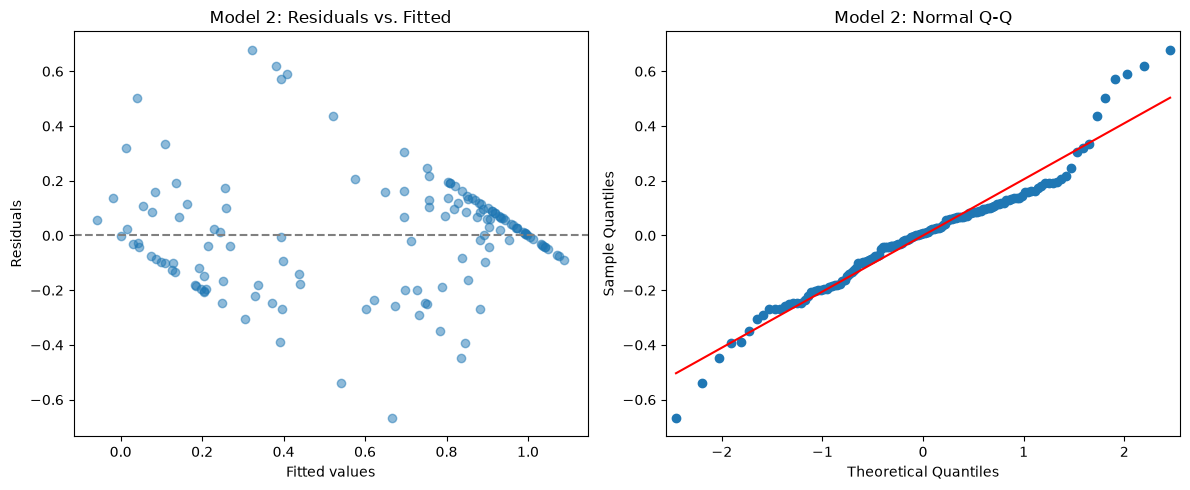

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

fitted2 = model2.fittedvalues
resid2 = model2.resid

ax.scatter(fitted2, resid2, alpha=0.5)
ax.axhline(0, linestyle='--', color='gray')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Model 2: Residuals vs. Fitted')


plt.tight_layout()
plt.show()


## 6. Evaluation of Significance

We evaluate both preregistered hypotheses at alpha = 0.05.


In [13]:
print('=' * 65)
print('Hypothesis 1 (Model 1 â€” temperature coefficient)')
print('=' * 65)
t1 = model1.params['temperature_c']
p1t = model1.pvalues['temperature_c']
p1p = model1.pvalues['precipitation_mm']
pr1 = model1.params['precipitation_mm']

print(f'  temperature_c:    coef = {t1:+.4f},  p = {p1t:.4f}')
if p1t < 0.05 and t1 < 0:
    print('  Result: REJECT H0 â€” negative and significant at alpha=0.05.')
    print('  Supports the preregistered direction (beta_temperature < 0).')
elif p1t < 0.05:
    print('  Result: REJECT H0 â€” significant at alpha=0.05 but POSITIVE.')
    print('  Contradicts the preregistered direction (beta_temperature < 0).')
else:
    print('  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.')
    print('  Insufficient evidence that temperature predicts log monthly sales.')

print()
print(f'  precipitation_mm: coef = {pr1:+.4f},  p = {p1p:.4f}')
if p1p < 0.05:
    print('  Result: REJECT H0 â€” significant at alpha=0.05.')
    print('  Supports the preregistered hypothesis (beta_precipitation != 0).')
else:
    print('  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.')
    print('  Insufficient evidence that precipitation predicts log monthly sales.')

print()
print('=' * 65)
print('Hypothesis 2 (Model 2 â€” temperature coefficient)')
print('=' * 65)
t2 = model2.params['temperature_c']
p2t = model2.pvalues['temperature_c']
p2p = model2.pvalues['precipitation_mm']
pr2 = model2.params['precipitation_mm']

print(f'  temperature_c:    coef = {t2:+.4f},  p = {p2t:.4f}')
if p2t < 0.05 and t2 > 0:
    print('  Result: REJECT H0 â€” positive and significant at alpha=0.05.')
    print('  Supports the preregistered direction (beta_temperature > 0).')
elif p2t < 0.05:
    print('  Result: REJECT H0 â€” significant at alpha=0.05 but NEGATIVE.')
    print('  Contradicts the preregistered direction (beta_temperature > 0).')
else:
    print('  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.')
    print('  Insufficient evidence that temperature predicts the cotton proportion.')

print()
print(f'  precipitation_mm: coef = {pr2:+.4f},  p = {p2p:.4f}')
if p2p < 0.05:
    print('  Result: precipitation is significant at alpha=0.05 in Model 2.')
else:
    print('  Result: precipitation is not significant at alpha=0.05 in Model 2.')


Hypothesis 1 (Model 1 â€” temperature coefficient)
  temperature_c:    coef = +0.0075,  p = 0.9061
  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.
  Insufficient evidence that temperature predicts log monthly sales.

  precipitation_mm: coef = +0.0063,  p = 0.2679
  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.
  Insufficient evidence that precipitation predicts log monthly sales.

Hypothesis 2 (Model 2 â€” temperature coefficient)
  temperature_c:    coef = -0.0078,  p = 0.6557
  Result: FAIL TO REJECT H0 â€” not significant at alpha=0.05.
  Insufficient evidence that temperature predicts the cotton proportion.

  precipitation_mm: coef = +0.0010,  p = 0.5049
  Result: precipitation is not significant at alpha=0.05 in Model 2.


## 7. Conclusions

Our two least squares models use identified-material sales from January 2014 to August 2026,
with calendar-month dummies and a linear year trend as controls.

**Model 1 (log monthly sales quantity):** The regression summary and the significance evaluation
in Section 6 show the direction and significance of the temperature and precipitation
coefficients. The model R-squared and F-statistic (in the summary header) describe
overall fit. If the month dummies explain most variance, the F-test on the full model
may be significant even if individual weather coefficients are not.

**Model 2 (cotton proportion):** The temperature coefficient tests whether warmer months
are associated with a higher cotton share of cotton-plus-wool sales. The direction and
significance are reported in Section 6.

**Answer to the research question:** Whether U.S. monthly temperature and precipitation
predict monthly hat sales and the cotton-wool mix depends on whether the coefficients
are statistically significant (see Section 6). If temperature is significant and negative
in Model 1, cooler months are associated with higher total identified-material sales.
If temperature is significant and positive in Model 2, warmer months shift the
identified-material mix toward cotton. The business's B2B sales model and the 88.1%
unknown-material rate mean these findings apply only to identified-material products
and may not reflect total demand.


## 8. Limitations

1. **B2B buying-ahead:** Many customers are retailers or wholesalers purchasing in
   advance of expected weather. Our models use contemporaneous weather; the true
   relationship may be lagged by one to three months. Future analysis could test
   lagged weather variables.

2. **Incomplete sales records:** Both accounting exports hit the 32,768-row limit,
   suggesting some transactions may be missing. Five months in the full period have
   no recorded sales at all. Systematic gaps could bias monthly totals in certain periods.

3. **Missing material information:** 88.1% of recorded quantity has unknown or
   ambiguous material. The cotton and wool products we can identify are not guaranteed
   to represent the full sales mix, and patterns in identified materials may not
   generalize to the whole business.

3. **National weather vs. local customers:** We use CONUS-wide average temperature and
   precipitation. Because the business ships nationally this is more appropriate than
   local Farmingdale weather, but regional variation means individual customers may
   experience very different conditions from the national average.


## 9. Acknowledgements and Bibliography

**Acknowledgements:** Sales and inventory data were provided by the owner of
angelawilliam.com. NOAA weather data are public domain.

**Bibliography**

1. National Oceanic and Atmospheric Administration (NOAA). *Monthly Climate Normals
   and Historical Data - U.S. Climate Divisional Dataset.*
   https://www.ncei.noaa.gov/access/monitoring/climate-at-a-glance/

2. Starr-McCluer, M. (2000). *The Effects of Weather on Retail Sales.* Board of
   Governors of the Federal Reserve System, Finance and Economics Discussion Series
   2000-08. https://doi.org/10.17016/FEDS.2000.08

3. National Retail Federation & Planalytics. (2024). *Climate-Proofing Retail:
   Turning Weather Into a Competitive Advantage.*
   https://nrf.com/research/climate-proofing-retail
